# Stylized facts of daily index returns

CAC 40 and S&P 500 daily closes, January 2010 to October 2026 (Yahoo Finance price indices, snapshot of 2026-10-21).

This notebook checks, on the data used by the project, the empirical properties that drive the modelling choices of the risk pipeline: return convention, time-varying volatility, volatility clustering and asymmetry, heavy tails, cross-market dependence, and the rate sensitivity of the bond position. Each section ends with its consequence for the pipeline.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from scipy import stats

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists())
RAW = ROOT / "data" / "raw" / "snapshots"

# Colour-blind-safe palette: blue = CAC 40, orange = S&P 500
BLUE, ORANGE, INK, INK2, GRID, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.figsize": (9, 3.4),
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "lines.linewidth": 1.5,
        "legend.frameon": False,
        "font.size": 9,
    }
)
PCT = mtick.PercentFormatter(1.0, decimals=0)

In [2]:
def load_prices() -> pd.DataFrame:
    """Daily closes, one column per index, from the local snapshot (downloaded if missing)."""
    files = sorted(RAW.glob("yahoo_indices_*.parquet"))
    if files:
        raw = pd.read_parquet(files[-1])
    else:
        import yfinance as yf

        frames = [
            yf.download(
                t, period="max", auto_adjust=False, actions=False, progress=False, multi_level_index=False
            )
            .rename(columns=str.lower)
            .rename_axis("date")
            .reset_index()
            .assign(ticker=t)
            for t in ["^FCHI", "^GSPC"]
        ]
        raw = pd.concat(frames)
        RAW.mkdir(parents=True, exist_ok=True)
        raw.to_parquet(RAW / f"yahoo_indices_{pd.Timestamp.today():%Y-%m-%d}.parquet", index=False)
    wide = raw.pivot(index="date", columns="ticker", values="close")
    return wide.rename(columns={"^FCHI": "CAC 40", "^GSPC": "S&P 500"})


prices = load_prices().loc["2010":]
cac = prices["CAC 40"].dropna()
simple = cac.pct_change().dropna()
log = np.log(cac).diff().dropna()
print(f"CAC 40: {len(simple)} daily returns, {simple.index[0]:%Y-%m-%d} to {simple.index[-1]:%Y-%m-%d}")

CAC 40: 4294 daily returns, 2010-01-05 to 2026-10-19


## 1. Return convention

Simple returns aggregate across positions (book P&L is the notional-weighted sum of simple returns); log returns aggregate over time. The gap between the two conventions on the CAC 40:

In [3]:
gap = (simple - log).abs()
worst = gap.idxmax()
print(f"median gap: {gap.median():.4%}")
print(f"largest gap: {gap.max():.2%} on {worst:%Y-%m-%d} (simple {simple[worst]:.2%}, log {log[worst]:.2%})")
print(f"\nfull-period change:           {cac.iloc[-1] / cac.iloc[0] - 1:+.1%}")
print(f"exp(sum of log returns) - 1:  {np.exp(log.sum()) - 1:+.1%}")
print(f"sum of simple returns:        {simple.sum():+.1%}")

median gap: 0.0018%
largest gap: 0.82% on 2020-03-12 (simple -12.28%, log -13.10%)

full-period change:           +96.0%
exp(sum of log returns) - 1:  +96.0%
sum of simple returns:        +99.0%


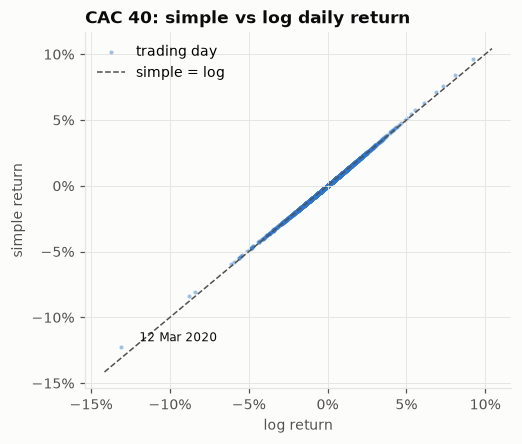

In [4]:
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.scatter(log, simple, s=7, color=BLUE, alpha=0.45, linewidths=0, label="trading day")
lims = np.array([log.min(), simple.max()]) * 1.08
ax.plot(lims, lims, color=INK2, linewidth=1, linestyle="--", label="simple = log")
ax.annotate(
    f"{worst:%d %b %Y}",
    (log[worst], simple[worst]),
    xytext=(12, 4),
    textcoords="offset points",
    color=INK,
    fontsize=8,
)
ax.set(title="CAC 40: simple vs log daily return", xlabel="log return", ylabel="simple return")
ax.xaxis.set_major_formatter(PCT)
ax.yaxis.set_major_formatter(PCT)
ax.legend(loc="upper left");

The two conventions agree to within 0.002% on a median day and diverge only on extreme moves (0.82 pp on 12 March 2020).

**Consequence:** book P&L is computed from simple returns; multi-day horizons use log returns.

## 2. Time-varying volatility

full-sample volatility: 1.21% daily, 19.3% annualised (sqrt(252) scaling)


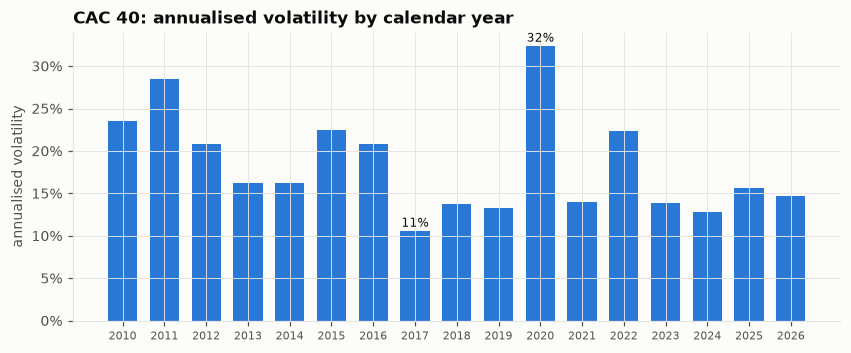

In [5]:
daily_vol = simple.std()
print(
    f"full-sample volatility: {daily_vol:.2%} daily, {daily_vol * np.sqrt(252):.1%} annualised (sqrt(252) scaling)"
)

annual = simple.groupby(simple.index.year).std() * np.sqrt(252)
fig, ax = plt.subplots()
ax.bar(annual.index, annual.values, color=BLUE, width=0.7)
for year in (annual.idxmin(), annual.idxmax()):
    ax.annotate(
        f"{annual[year]:.0%}",
        (year, annual[year]),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        color=INK,
        fontsize=8,
    )
ax.set(title="CAC 40: annualised volatility by calendar year", ylabel="annualised volatility")
ax.yaxis.set_major_formatter(PCT)
ax.set_xticks(annual.index)
ax.tick_params(axis="x", labelsize=7);

Annualised volatility ranges from 10.5% (2017) to 32.3% (2020).

**Consequence:** a single unconditional volatility misstates risk in most years; VaR is driven by conditional volatility forecasts (EWMA, GARCH, HAR).

## 3. Volatility clustering and asymmetry

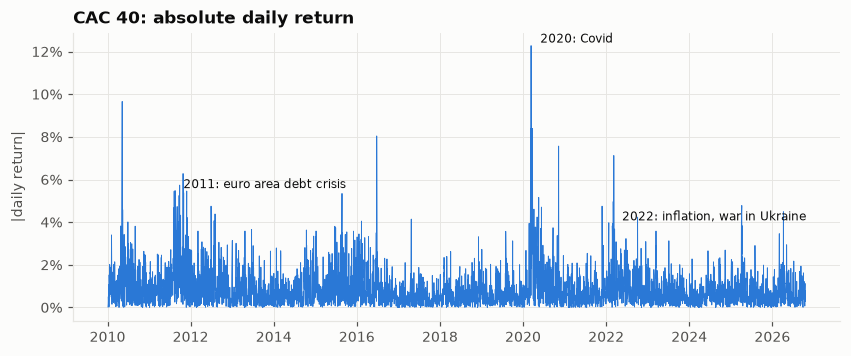

In [6]:
fig, ax = plt.subplots()
ax.plot(simple.index, simple.abs(), color=BLUE, linewidth=0.6)
for label, date in [
    ("2011: euro area debt crisis", "2011-08-10"),
    ("2020: Covid", "2020-03-12"),
    ("2022: inflation, war in Ukraine", "2022-03-01"),
]:
    ax.annotate(
        label,
        (pd.Timestamp(date), simple.abs().loc[date:].iloc[0]),
        xytext=(6, 2),
        textcoords="offset points",
        color=INK,
        fontsize=8,
    )
ax.set(title="CAC 40: absolute daily return", ylabel="|daily return|")
ax.yaxis.set_major_formatter(PCT);

In [7]:
next5 = simple.abs().rolling(5).mean().shift(-5)  # mean absolute return over the next 5 days
big_down, big_up = simple <= simple.quantile(0.05), simple >= simple.quantile(0.95)
pd.Series(
    {
        "autocorrelation of returns (lag 1)": simple.autocorr(1),
        "autocorrelation of |returns| (lag 1)": simple.abs().autocorr(1),
        "next-5-day mean |return| after the 5% worst days": next5[big_down].mean(),
        "next-5-day mean |return| after the 5% best days": next5[big_up].mean(),
        "next-5-day mean |return|, all days": next5.mean(),
    }
).round(4).to_frame("value")

,value
autocorrelation of returns (lag 1),-0.0062
autocorrelation of |returns| (lag 1),0.2096
next-5-day mean |return| after the 5% worst days,0.0147
next-5-day mean |return| after the 5% best days,0.0109
"next-5-day mean |return|, all days",0.0084


Returns show no first-order autocorrelation, absolute returns do: the size of moves is forecastable, their direction is not. Volatility is higher after large falls than after large rises of the same rank (leverage effect).

**Consequence:** the pipeline forecasts volatility, not returns. The asymmetry is a known weakness of symmetric models such as EWMA and is checked in the volatility model comparison.

## 4. Heavy tails

In [8]:
z = (simple - simple.mean()) / simple.std()
expected = len(z) * 2 * stats.norm.sf(4)
print(f"kurtosis: {stats.kurtosis(simple, fisher=False):.1f} (normal: 3), skewness: {stats.skew(simple):.2f}")
print(f"days beyond 4 standard deviations: {(z.abs() > 4).sum()} (expected under normality: {expected:.2f})")
print("\nfive largest falls:")
print(simple.nsmallest(5).map("{:.1%}".format).to_string())

kurtosis: 10.5 (normal: 3), skewness: -0.31
days beyond 4 standard deviations: 20 (expected under normality: 0.27)

five largest falls:
date
2020-03-12    -12.3%
2020-03-09     -8.4%
2016-06-24     -8.0%
2020-03-18     -5.9%
2020-03-16     -5.8%


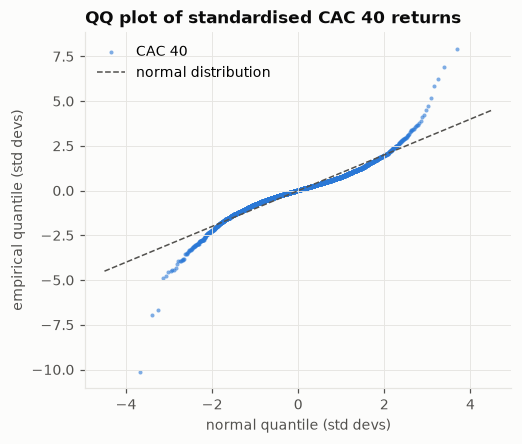

In [9]:
theoretical = stats.norm.ppf((np.arange(1, len(z) + 1) - 0.5) / len(z))
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.scatter(theoretical, np.sort(z), s=7, color=BLUE, alpha=0.6, linewidths=0, label="CAC 40")
ax.plot([-4.5, 4.5], [-4.5, 4.5], color=INK2, linewidth=1, linestyle="--", label="normal distribution")
ax.set(
    title="QQ plot of standardised CAC 40 returns",
    xlabel="normal quantile (std devs)",
    ylabel="empirical quantile (std devs)",
)
ax.legend(loc="upper left");

Kurtosis is about 10 against 3 under normality, with 20 days beyond four standard deviations where a normal distribution expects fewer than one. The 12 March 2020 fall is about ten standard deviations.

**Consequence:** a normal parametric VaR understates tail losses; it is benchmarked against historical and filtered historical simulation.

## 5. Cross-market dependence

Returns are computed on days when both markets traded.

In [10]:
rets = prices.dropna().pct_change().dropna()
cac_r, spx_r = rets["CAC 40"], rets["S&P 500"]

rows = {}
for label, start, end in [
    ("2019", "2019-01-01", "2019-12-31"),
    ("March 2020", "2020-03-01", "2020-03-31"),
    ("2022", "2022-01-01", "2022-12-31"),
    ("2010-2026", None, None),
]:
    c, s = cac_r.loc[start:end], spx_r.loc[start:end]
    rows[label] = {"days": len(c), "same day": c.corr(s), "CAC(t) vs S&P(t-1)": c.corr(s.shift(1))}
pd.DataFrame(rows).T.astype({"days": int}).round(3)

,days,same day,CAC(t) vs S&P(t-1)
2019,249,0.729,0.027
March 2020,22,0.724,-0.103
2022,250,0.517,0.193
2010-2026,4181,0.581,0.144


The 2019 vs March 2020 comparison shows no increase in same-day correlation; a 22-day window is too short for a stable estimate. A full-sample view: rolling 60-day correlation, averaged by quartile of rolling volatility.

In [11]:
roll_corr = cac_r.rolling(60).corr(spx_r)
roll_vol = cac_r.rolling(60).std() * np.sqrt(252)
quartile = pd.qcut(roll_vol.dropna(), 4, labels=["Q1 (calmest)", "Q2", "Q3", "Q4 (most volatile)"])
roll_corr.loc[quartile.index].groupby(quartile, observed=True).mean().round(2).rename_axis(
    "volatility quartile"
).to_frame("mean 60-day correlation")

,mean 60-day correlation
volatility quartile,
Q1 (calmest),0.49
Q2,0.52
Q3,0.59
Q4 (most volatile),0.63


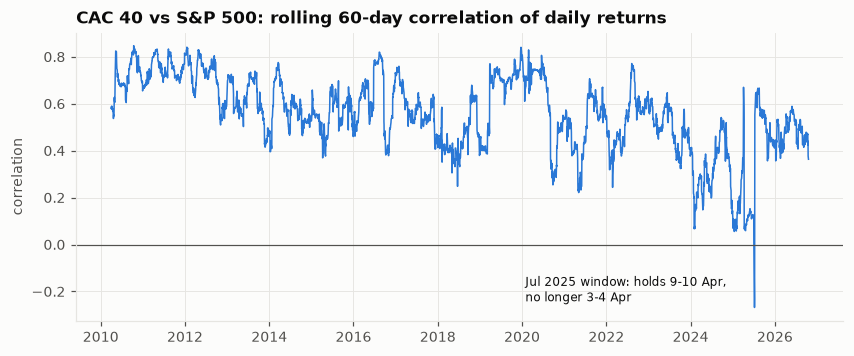

In [12]:
fig, ax = plt.subplots()
ax.plot(roll_corr.index, roll_corr, color=BLUE, linewidth=1)
ax.axhline(0, color=INK2, linewidth=0.8)
low = roll_corr.idxmin()
ax.annotate(
    f"{low:%b %Y} window: holds 9-10 Apr,\nno longer 3-4 Apr",
    (low, roll_corr[low]),
    xytext=(-150, 4),
    textcoords="offset points",
    color=INK,
    fontsize=8,
)
ax.set(title="CAC 40 vs S&P 500: rolling 60-day correlation of daily returns", ylabel="correlation");

In [13]:
rets.loc["2025-04-02":"2025-04-11"].map("{:+.1%}".format)

ticker,CAC 40,S&P 500
date,,
2025-04-02,-0.2%,+0.7%
2025-04-03,-3.3%,-4.8%
2025-04-04,-4.3%,-6.0%
2025-04-07,-4.8%,-0.2%
2025-04-08,+2.5%,-1.6%
2025-04-09,-3.3%,+9.5%
2025-04-10,+3.8%,-3.5%
2025-04-11,-0.3%,+1.8%


- **Stress dependence:** correlation rises with volatility, from 0.49 in the calmest quartile to 0.63 in the most volatile one.
- **Asynchronous closes:** Paris closes at 17:30 CET, New York at 22:00 CET. US news released after the Paris close shows up in next-day CAC 40 returns, so the lagged correlation is positive over the full sample and same-day correlation understates the true dependence.
- **Outliers:** the July 2025 trough originates in April 2025. On 3-4 April both indices fell sharply; on 9 April the S&P 500 rose 9.5% after the Paris close while the CAC 40 fell 3.3%, then recovered 3.8% the next day. Once 3-4 April left the 60-day window, the two out-of-sync days pushed the estimate below zero.
- **Trend:** the dependence weakened over the sample, from about 0.8 in 2010-2011 to 0.4-0.5 recently.

**Consequence:** diversification shrinks in stress, and same-day correlation alone understates joint risk. Historical simulation on book P&L captures joint moves directly; parametric methods need this caveat.

## 6. Bond position: duration vs convexity

10-year zero-coupon bond, price `100 / (1 + y)^10`, at an illustrative 2.5% yield (the euro area AAA 10-year yield is ingested by the pipeline).

In [14]:
T, y, dy = 10, 0.025, 0.01


def bond_price(yld: float) -> float:
    return 100 / (1 + yld) ** T


D = T / (1 + y)  # modified duration
C = T * (T + 1) / (1 + y) ** 2  # convexity
rows = {}
for label, shift in [("+100 bp", dy), ("-100 bp", -dy)]:
    exact = bond_price(y + shift) / bond_price(y) - 1
    rows[label] = {
        "exact": exact,
        "duration": -D * shift,
        "duration + convexity": -D * shift + 0.5 * C * shift**2,
    }
(pd.DataFrame(rows).T * 100).round(2).add_suffix(" (%)")

,exact (%),duration (%),duration + convexity (%)
+100 bp,-9.25,-9.76,-9.23
-100 bp,10.30,9.76,10.28


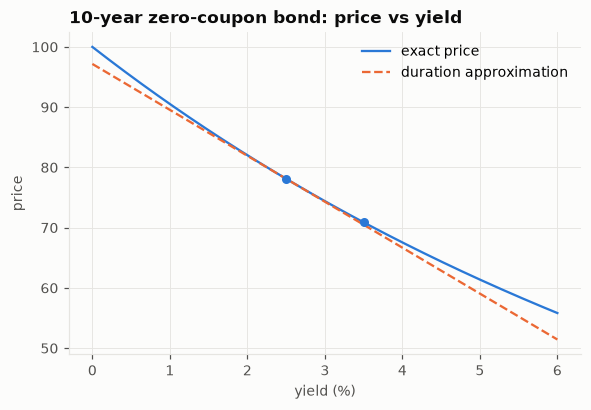

In [15]:
grid = np.linspace(0.0, 0.06, 200)
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(grid * 100, [bond_price(g) for g in grid], color=BLUE, label="exact price")
ax.plot(
    grid * 100,
    bond_price(y) * (1 - D * (grid - y)),
    color=ORANGE,
    linestyle="--",
    label="duration approximation",
)
ax.scatter([y * 100, (y + dy) * 100], [bond_price(y), bond_price(y + dy)], color=BLUE, s=24, zorder=3)
ax.set(title="10-year zero-coupon bond: price vs yield", xlabel="yield (%)", ylabel="price")
ax.legend();

Duration overstates the loss for a rise in yields (−9.76% vs −9.25% for +100 bp) and understates the gain for a fall (+9.76% vs +10.30%); the convexity term removes most of the error.

**Consequence:** the bond position is fully revalued from the yield rather than approximated with duration. Euro yields were negative for long periods between 2015 and 2021, so yields are modelled in changes, never in logs.

## Summary

| Fact | Evidence (CAC 40, 2010-2026) | Consequence for the pipeline |
|---|---|---|
| Simple ≈ log returns on normal days | Median gap 0.002%, 0.82 pp on 12 March 2020 | Simple returns for book P&L, log returns over time |
| Time-varying volatility | 10.5% (2017) to 32.3% (2020) annualised | Conditional volatility forecasts |
| Clustering, leverage effect | Autocorrelation 0.21 for \|r\|, about 0 for r | Forecast volatility, not returns |
| Heavy tails | Kurtosis ≈ 10; 20 days beyond 4σ vs 0.27 expected | Normal VaR benchmarked against (filtered) historical simulation |
| Stress dependence, async closes | 60-day correlation 0.49 → 0.63 from calm to volatile quartile; lagged correlation 0.14 | Historical simulation on book P&L; caveat on same-day correlation |
| Bond convexity | Duration error 0.5 pp for ±100 bp | Full revaluation of the bond, yields in changes |